# Regression: predicting each participant's food ratings from EEG

**Question:** while a participant looks at a food image, can we predict **how they rate it** (0–100) from their EEG? We do this separately for the three attributes:

| Target | Rating prompt (after the EEG task) | Matching EEG question |
|---|---|---|
| `healthiness` | "How healthy is this food?" | Healthy? |
| `tastiness` | "How tasty is this food?" | Tasty? |
| `willingness` | "How much would you like to eat this food?" | Like to eat? |

This is what the article does (linear SVR on continuous ratings, Fig. 2E–F). It is a **regression** problem, unlike the Yes/No classification in `classifiers_benchmark_Rafaela.ipynb`.

**Setup (kept identical to the classification benchmark so results are comparable):**
- Data: 6 subjects, 360 `display` trials each (120 images × 3 views). With `AVERAGE_VIEWS = True` (default), the 3 views of each image are averaged → 120 cleaner examples per subject. Each example gets the participant's own rating for that image.
- Features: two sets compared: the mean EEG of each electrode between 200 and 500 ms (64 features, as in the classification benchmark), and 9 windows of 100 ms from 100 to 1000 ms (576 features). Section 8 adds a time-resolved analysis.
- Models: least squares, PCA + least squares, ridge, PCA + ridge, lasso, elastic net (ridge + lasso), linear SVR, RBF SVR, and a baseline that always predicts the training mean.
- Validation: nested cross-validation grouped by image. The outer 5 folds measure performance, and the inner 5 folds choose the hyperparameters (grids widened after the first runs). The 3 trials of an image are always in the same fold.
- Score: **Pearson r** between predicted and true ratings (the article's measure). Chance level is r = 0, checked with shuffled ratings per subject and with a test across subjects. We also report R² and RMSE.

In [1]:
import time
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error

from outils import load_subject

DATA_FILE = Path.home() / "Library/CloudStorage/GoogleDrive-firyal.elalj@epfl.ch/Mon Drive/epoch_data_6sujets.nc"
RATINGS_DIR = Path("ratings")      # per-participant CSVs from OSF: ratings/in-person/FOODEEG_pXXX_ratings.csv
SUBJECTS = ["sub-006", "sub-008", "sub-009", "sub-013", "sub-014", "sub-015"]
TARGETS = {"healthiness": "rating_healthiness",
           "tastiness": "rating_tastiness",
           "willingness": "rating_willingnessToEat"}

# True: average the 3 views of each image -> 120 examples per subject (less noise)
# False: keep the 360 single trials (the 3 views of an image share the same rating)
AVERAGE_VIEWS = True
VERSION = "avg3" if AVERAGE_VIEWS else "360"     # used in the names of the saved files

# Feature sets: list of (start, end) windows in ms; the mean of each electrode in each window is a feature
FEATURE_SETS = {
    "200–500 ms": [(200, 500)],                                   # 64 features
    "9 windows": [(t, t + 100) for t in range(100, 1000, 100)],   # 100-200, ..., 900-1000 ms: 576 features
}

## 1. The targets: each participant's ratings

The ratings are **not** in `epoch_data_6sujets.nc`. They come from the dataset's OSF page (https://osf.io/y9pmf, folder `ratings/in-person`), one CSV per participant: `FOODEEG_p006_ratings.csv` belongs to `sub-006`. Each participant rated all 120 images on the three attributes after the EEG task.

`stimCode` n corresponds to `foodImage.n` in the EEG file (the image paths match for all 6 subjects).

In [2]:
def load_ratings(subject):
    """Return a DataFrame indexed by image code ("foodImage.n") with the 3 ratings (0-100)."""
    number = subject.replace("sub-", "")
    r = pd.read_csv(RATINGS_DIR / f"FOODEEG_p{number}_ratings.csv")
    r.index = "foodImage." + r["stimCode"].astype(str)
    return r[list(TARGETS.values())].rename(columns={v: k for k, v in TARGETS.items()})


ratings = load_ratings("sub-006")
ratings.head()

,healthiness,tastiness,willingness
stimCode,,,
foodImage.1,7,94,87
foodImage.2,13,87,71
foodImage.3,3,75,63
foodImage.4,9,68,68
foodImage.5,4,89,77


**Check:** are the attributes really different targets? Correlation between the three ratings of each participant, across the 120 images:

In [3]:
rows = []
for sub in SUBJECTS:
    c = load_ratings(sub).corr()
    rows.append({"subject": sub,
                 "health–taste": c.loc["healthiness", "tastiness"],
                 "health–willing": c.loc["healthiness", "willingness"],
                 "taste–willing": c.loc["tastiness", "willingness"]})
pd.DataFrame(rows).set_index("subject").round(2)

,health–taste,health–willing,taste–willing
subject,,,
sub-006,0.42,0.53,0.93
sub-008,-0.20,-0.03,0.78
sub-009,0.18,0.19,0.94
sub-013,0.26,0.28,0.99
sub-014,0.50,0.48,0.96
sub-015,0.57,0.59,0.94


**Tastiness and willingness are almost the same target** (r ≈ 0.8–0.99): people want to eat what they find tasty. Healthiness is much more independent. So we should expect similar results for tastiness and willingness, and interpret them together.

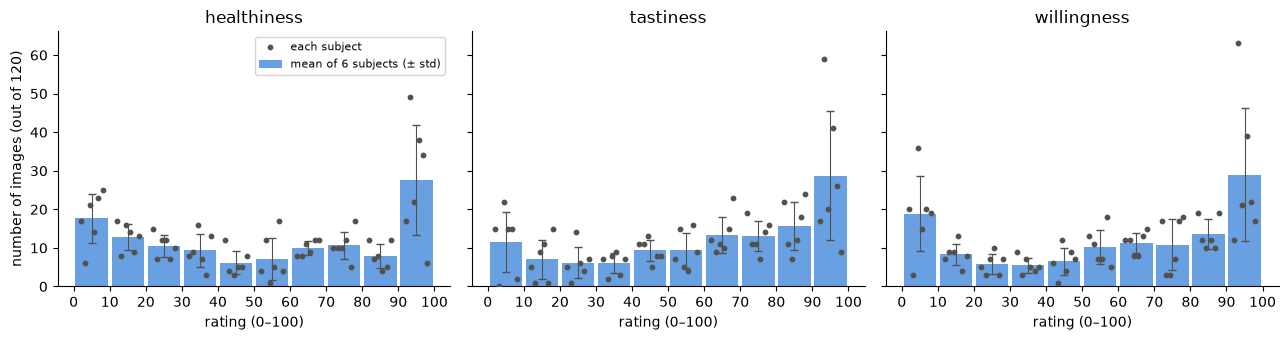

In [4]:
bins = np.arange(0, 101, 10)                      # 0-10, 10-20, ..., 90-100
centres = bins[:-1] + 5
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, target in zip(axes, TARGETS):
    # counts[i, j] = number of images that subject i rated in bin j
    counts = np.array([np.histogram(load_ratings(sub)[target], bins=bins)[0] for sub in SUBJECTS])
    mean, std = counts.mean(axis=0), counts.std(axis=0)
    ax.bar(centres, mean, width=9, color="#2a78d6", alpha=0.7, yerr=std, capsize=3,
           error_kw={"ecolor": "#52514e", "linewidth": 0.8}, label="mean of 6 subjects (± std)")
    for i, sub in enumerate(SUBJECTS):              # one small dot per subject, slightly offset
        ax.scatter(centres + (i - 2.5) * 1.2, counts[i], s=10, color="#52514e", zorder=3,
                   label="each subject" if i == 0 else None)
    ax.set(title=target, xlabel="rating (0–100)", xticks=bins)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("number of images (out of 120)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. The features

`load_subject` gives the 360 `display` trials (−100 → 1000 ms) and their image codes.

**Averaging the 3 views (`AVERAGE_VIEWS = True`).** Each image was seen 3 times, and the 3 EEG responses differ mostly by random noise. Averaging them keeps the part of the response common to the image and cancels part of the noise → one row per image (120 rows). The number of independent ratings is still 120, but each example is cleaner. With ridge on 200–500 ms this raised the mean r from 0.09 (360 single trials) to 0.15.

**Two feature sets are compared (`FEATURE_SETS`):**

| Name | Windows | Features per row |
|---|---|---|
| `200–500 ms` | one window, 200–500 ms (as in the classification benchmark) | 64 |
| `9 windows` | 100–200, 200–300, …, 900–1000 ms | 64 × 9 = 576 |

The article finds rating information **from about 150 ms until 1000 ms**, and different moments can carry different information, so the 9-window version gives the model much more of the signal. With 576 features and only 96 training images per fold, there are more features than examples: least squares cannot work well there, and regularisation (ridge, lasso…) becomes essential.

All 9 windows are used together, so we do **not** pick windows by looking at the results (that would make the scores optimistic).

In [5]:
@lru_cache(maxsize=None)
def eeg(subject):
    """EEG of the 360 display trials and their image codes (read once per subject, then cached)."""
    X, _, images = load_subject(subject, data_file=DATA_FILE)
    return X, images


def subject_data(subject, target, windows=FEATURE_SETS["200–500 ms"], average=AVERAGE_VIEWS):
    """Return X, y (ratings for `target`) and the image code of each row.

    X = mean EEG of each electrode in each window, concatenated: (n_rows, 64 * n_windows).
    average=False: one row per trial (360). average=True: one row per image (120) = mean of its 3 trials.
    """
    X, images = eeg(subject)
    features = np.concatenate([X.sel(time_ms=slice(a, b)).mean(dim="time_ms").values for a, b in windows], axis=1)
    if average:
        unique_images = np.unique(images)
        features = np.array([features[images == image].mean(axis=0) for image in unique_images])
        images = unique_images
    y = load_ratings(subject).loc[images, target].values.astype(float)
    return features, y, images


for name, windows in FEATURE_SETS.items():
    X_feat, y, images = subject_data("sub-006", "healthiness", windows)
    print(f"{name:<11} X: {X_feat.shape}  y: {y.shape}  images: {len(np.unique(images))}")

200–500 ms  X: (120, 64)  y: (120,)  images: 120
9 windows   X: (120, 576)  y: (120,)  images: 120


## 3. The models

Every model is a pipeline `StandardScaler → regressor`, wrapped in `TransformedTargetRegressor` so the ratings are also standardised (mean 0, std 1) during training. This puts the hyperparameters on the same scale for every subject, and predictions are converted back to 0–100 automatically.

| Model | Course idea | Hyperparameters tuned (inner CV) |
|---|---|---|
| Mean baseline | predicts the training mean: r = 0, R² ≈ 0 (sanity check of the scoring) | – |
| Least squares | ordinary least squares, no penalty | – |
| PCA + least squares | keep the first k principal components of the EEG features, then least squares on them (principal component regression) | `n_components` (k) |
| Ridge | least squares + L2 penalty λ‖w‖² | `alpha` (λ) |
| PCA + ridge | first k principal components, then ridge | `n_components`, `alpha` |
| Lasso | least squares + L1 penalty λ‖w‖₁ (sets some weights to 0) | `alpha` |
| Elastic net | L1 + L2 (ridge + lasso) | `alpha`, `l1_ratio` |
| Linear SVR | SVM for regression, ε-insensitive loss (the article's model) | `C` |
| RBF SVR | SVM with a Gaussian kernel (non-linear) | `C`, `gamma` |

**Grids widened (step 3).** In the first runs, ridge often chose the largest α (10⁵) and linear SVR the smallest C (10⁻⁴), i.e. the edge of the grid: the best value may have been outside. The grids below go further in those directions. Section 6 checks automatically how often the chosen value is still at an edge.

**PCA (principal component analysis).** The features are strongly redundant: neighbouring electrodes record almost the same signal, and neighbouring windows are correlated. PCA finds the directions of largest variance in X and keeps only the first k of them, so the regression works on k ≪ 576 inputs. Two remarks:
- PCA is **unsupervised**: it keeps the directions where the EEG varies most, which are not necessarily the directions that relate to the ratings. Ridge does something similar but "softer": it shrinks the low-variance directions instead of removing them.
- PCA is inside the pipeline, so it is **fitted on the training images only** in each fold (no information from the test images leaks into it).

How much of the EEG variance do the first components capture? (sub-006, both feature sets)

200–500 ms : 13 components explain 90% of the variance (out of 64 features)
9 windows  : 39 components explain 90% of the variance (out of 576 features)


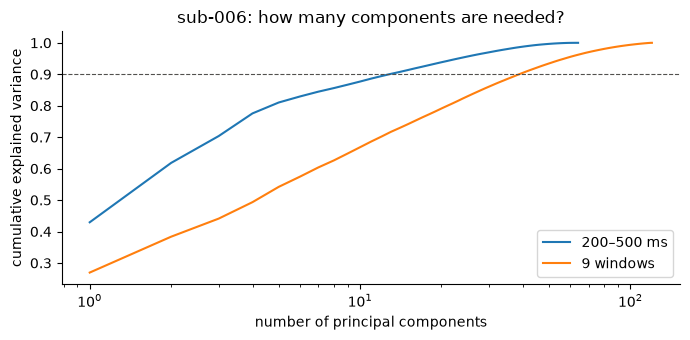

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for features, windows in FEATURE_SETS.items():
    X_feat, _, _ = subject_data("sub-006", "healthiness", windows)
    pca = PCA().fit(StandardScaler().fit_transform(X_feat))
    cumulative = np.cumsum(pca.explained_variance_ratio_)
    ax.plot(np.arange(1, len(cumulative) + 1), cumulative, label=features)
    k90 = int(np.searchsorted(cumulative, 0.9)) + 1
    print(f"{features:<11}: {k90} components explain 90% of the variance (out of {X_feat.shape[1]} features)")
ax.axhline(0.9, color="#52514e", linewidth=0.8, linestyle="--")
ax.set(xscale="log", xlabel="number of principal components", ylabel="cumulative explained variance",
       title="sub-006: how many components are needed?")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The models and their grids:

In [7]:
def model(*steps):
    """Standardise X and y, then apply `steps` (e.g. PCA(), Ridge())."""
    return TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), *steps),
                                      transformer=StandardScaler())

P = "regressor__"                      # prefix to reach the pipeline inside TransformedTargetRegressor
models = {
    "Mean baseline": (model(DummyRegressor()), {}),
    "Least squares": (model(LinearRegression()), {}),
    "PCA + least squares": (model(PCA(), LinearRegression()), {P + "pca__n_components": [1, 2, 5, 10, 20, 40, 60]}),
    "Ridge":         (model(Ridge()), {P + "ridge__alpha": np.logspace(-1, 8, 10)}),
    "PCA + ridge":   (model(PCA(), Ridge()), {P + "pca__n_components": [5, 10, 20, 40, 60],
                                              P + "ridge__alpha": np.logspace(-1, 6, 8)}),
    "Lasso":         (model(Lasso(max_iter=10000)), {P + "lasso__alpha": np.logspace(-3, 0.5, 8)}),
    "Elastic net":   (model(ElasticNet(max_iter=10000)), {P + "elasticnet__alpha": np.logspace(-3, 1, 5),
                                                         P + "elasticnet__l1_ratio": [0.1, 0.5, 0.9]}),
    "Linear SVR":    (model(SVR(kernel="linear")), {P + "svr__C": np.logspace(-7, -1, 7)}),
    "RBF SVR":       (model(SVR(kernel="rbf")), {P + "svr__C": [0.01, 0.1, 1, 10, 100, 1000],
                                                 P + "svr__gamma": ["scale", 1e-4, 1e-3, 1e-2]}),
}

## 4. Evaluation: nested cross-validation grouped by image

For each outer fold (5): the inner `GridSearchCV` picks the hyperparameters on the training images only, the model is refit, and it predicts the ratings of the **held-out images**. Every row then has an out-of-fold prediction, and we compute:
- **Pearson r** (main score, as in the article): does the prediction go up when the true rating goes up? 0 = chance. Computed **inside each test fold** and averaged over the 5 folds (via Fisher z, as in the article). If a model predicts a constant (e.g. lasso removing every electrode), r is set to 0.

  ⚠️ Why not one r over all out-of-fold predictions? Because each fold predicts around its own training mean, and a fold whose test images have high ratings has a lower training mean. Pooling the folds then gives a **negative** r (≈ −0.13 here) even for a model with no information, such as the mean baseline. Per-fold r avoids this bias.
- **R²**: fraction of the rating variance explained. Can be negative (worse than predicting the mean).
- **RMSE**: typical error in rating points. With a small r, RMSE can only drop a little: even a perfectly calibrated model has RMSE = std(ratings) × √(1 − r²), i.e. only 1% below the baseline for r = 0.15.

In [8]:
def pearson(y_true, y_pred):
    """Pearson correlation; 0 if the predictions are constant."""
    if np.std(y_pred) < 1e-12:
        return 0.0
    return float(np.corrcoef(y_true, y_pred)[0, 1])


def nested_cv(pipeline, grid, X, y, groups, seed=0):
    """Out-of-fold predictions with grouped nested CV.
    Returns (predictions, fold number of each row, chosen params per fold)."""
    outer = GroupKFold(n_splits=5, shuffle=True, random_state=seed)
    inner = GroupKFold(n_splits=5, shuffle=True, random_state=seed + 1)
    y_pred = np.empty_like(y)
    fold = np.empty(len(y), dtype=int)
    chosen = []
    for k, (train, test) in enumerate(outer.split(X, y, groups)):
        fold[test] = k
        if grid:
            search = GridSearchCV(pipeline, grid, cv=inner, scoring="neg_mean_squared_error", n_jobs=-1)  # all CPU cores
            search.fit(X[train], y[train], groups=groups[train])
            fitted, params = search.best_estimator_, search.best_params_
        else:
            fitted, params = pipeline.fit(X[train], y[train]), {}
        y_pred[test] = fitted.predict(X[test])
        chosen.append({name.split("__")[-1]: v for name, v in params.items()})
    return y_pred, fold, chosen


def scores(y, y_pred, fold):
    """r = mean of the per-fold correlations (Fisher z); R2 and RMSE on all out-of-fold predictions."""
    z = [np.arctanh(np.clip(pearson(y[fold == k], y_pred[fold == k]), -0.999, 0.999)) for k in np.unique(fold)]
    return {"r": float(np.tanh(np.mean(z))),
            "R2": r2_score(y, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y, y_pred)))}


# Quick test on one subject, one target, one model
X_feat, y, images = subject_data("sub-006", "healthiness")
pipe, grid = models["Ridge"]
y_pred, fold, chosen = nested_cv(pipe, grid, X_feat, y, images)
print(scores(y, y_pred, fold), chosen)

{'r': 0.43950147887075225, 'R2': 0.16397498139686761, 'RMSE': 29.498141548324213} [{'alpha': np.float64(100.0)}, {'alpha': np.float64(100.0)}, {'alpha': np.float64(100.0)}, {'alpha': np.float64(10.0)}, {'alpha': np.float64(10.0)}]


## 5. Run everything: 6 subjects × 2 feature sets × 3 targets × 9 models

In [9]:
results = []
predictions = {}                    # (subject, features, target, model) -> (true, predicted) ratings

t_start = time.time()
for sub in SUBJECTS:
    for features, windows in FEATURE_SETS.items():
        for target in TARGETS:
            X_feat, y, images = subject_data(sub, target, windows)
            for name, (pipe, grid) in models.items():
                t0 = time.time()
                y_pred, fold, chosen = nested_cv(pipe, grid, X_feat, y, images)
                predictions[sub, features, target, name] = (y, y_pred)
                results.append({"subject": sub, "features": features, "target": target, "model": name,
                                **scores(y, y_pred, fold), "params": chosen, "time_s": time.time() - t0})
    print(f"{sub} done ({time.time() - t_start:.0f} s)")

df = pd.DataFrame(results)

/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.539724e-02, tolerance: 7.600e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.114014e-02, tolerance: 7.700e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consi

/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.613870e-02, tolerance: 7.700e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.518502e-02, tolerance: 7.700e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consi

/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.123912e-02, tolerance: 7.700e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.766079e-02, tolerance: 7.700e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consi

/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.551834e-02, tolerance: 7.700e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.362355e-02, tolerance: 7.700e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consi

/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.184442e-03, tolerance: 7.600e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.173715e-02, tolerance: 7.700e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consi

/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.949553e-02, tolerance: 7.700e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.094328e-02, tolerance: 7.700e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consi

... (127 outputs left out)

/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.191337e-02, tolerance: 7.700e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.866801e-02, tolerance: 7.600e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consi

/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.268508e-02, tolerance: 7.600e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.024063e-02, tolerance: 7.700e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consi

/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.297524e-02, tolerance: 7.600e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.946744e-02, tolerance: 7.700e-03
  model = cd_fast.enet_coordinate_descent(
/opt/miniconda3/envs/ml-project1/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consi

sub-015 done (171 s)


## 6. Results

In [10]:
summary = (df.groupby(["target", "features", "model"], sort=False)
             .agg(mean_r=("r", "mean"), std_r=("r", "std"),
                  n_r_above_0=("r", lambda r: int((r > 0).sum())),
                  mean_R2=("R2", "mean"), mean_RMSE=("RMSE", "mean"))
             .round(3))
summary

mean_r  std_r  n_r_above_0  \
target      features   model                                             
healthiness 200–500 ms Mean baseline         0.000  0.000            0   
                       Least squares         0.044  0.233            3   
                       PCA + least squares   0.134  0.177            5   
                       Ridge                 0.127  0.195            4   
                       PCA + ridge           0.132  0.183            4   
                       Lasso                 0.117  0.189            2   
                       Elastic net           0.118  0.197            3   
                       Linear SVR            0.129  0.191            5   
                       RBF SVR               0.129  0.178            4   
tastiness   200–500 ms Mean baseline         0.000  0.000            0   
                       Least squares         0.015  0.170            3   
                       PCA + least squares   0.130  0.167            5   
                       Ridge                 0.165  0.121            6   
                       PCA + ridge           0.173  0.123            6   
                       Lasso                 0.048  0.138            2   
                       Elastic net           0.047  0.127            4   
                       Linear SVR            0.156  0.128            5   
                       RBF SVR               0.091  0.096            5   
willingness 200–500 ms Mean baseline         0.000  0.000            0   
                       Least squares         0.037  0.128            3   
                       PCA + least squares   0.093  0.215            4   
                       Ridge                 0.156  0.154            5   
                       PCA + ridge           0.154  0.161            5   
                       Lasso                 0.050  0.152            3   
                       Elastic net           0.052  0.164            3   
                       Linear SVR            0.111  0.177            4   
                       RBF SVR               0.061  0.130            3   
healthiness 9 windows  Mean baseline         0.000  0.000            0   
                       Least squares         0.032  0.176            3   
                       PCA + least squares   0.056  0.146            3   
                       Ridge                 0.075  0.216            3   
                       PCA + ridge           0.057  0.206            3   
                       Lasso                 0.015  0.040            2   
                       Elastic net           0.069  0.155            3   
                       Linear SVR            0.090  0.189            4   
                       RBF SVR               0.033  0.182            4   
tastiness   9 windows  Mean baseline         0.000  0.000            0   
                       Least squares         0.178  0.204            5   
                       PCA + least squares   0.172  0.173            5   
                       Ridge                 0.209  0.174            5   
                       PCA + ridge           0.185  0.178            5   
                       Lasso                 0.135  0.179            5   
                       Elastic net           0.129  0.195            4   
                       Linear SVR            0.201  0.152            6   
                       RBF SVR               0.115  0.192            4   
willingness 9 windows  Mean baseline         0.000  0.000            0   
                       Least squares         0.133  0.215            4   
                       PCA + least squares   0.175  0.195            5   
                       Ridge                 0.209  0.183            5   
                       PCA + ridge           0.206  0.183            6   
                       Lasso                 0.143  0.173            4   
                       Elastic net           0.134  0.210            4   
                       Linear SVR            0.2

Mean r, all in one table (rows: model, columns: target × feature set):

In [11]:
(df.pivot_table(index="model", columns=["target", "features"], values="r", aggfunc="mean", sort=False)
   .loc[list(models)].round(3))

target,healthiness,tastiness,willingness,healthiness,tastiness,willingness
features,200–500 ms,200–500 ms,200–500 ms,9 windows,9 windows,9 windows
model,,,,,,
Mean baseline,0.000,0.000,0.000,0.000,0.000,0.000
Least squares,0.044,0.015,0.037,0.032,0.178,0.133
PCA + least squares,0.134,0.130,0.093,0.056,0.172,0.175
Ridge,0.127,0.165,0.156,0.075,0.209,0.209
PCA + ridge,0.132,0.173,0.154,0.057,0.185,0.206
Lasso,0.117,0.048,0.050,0.015,0.135,0.143
Elastic net,0.118,0.047,0.052,0.069,0.129,0.134
Linear SVR,0.129,0.156,0.111,0.090,0.201,0.200


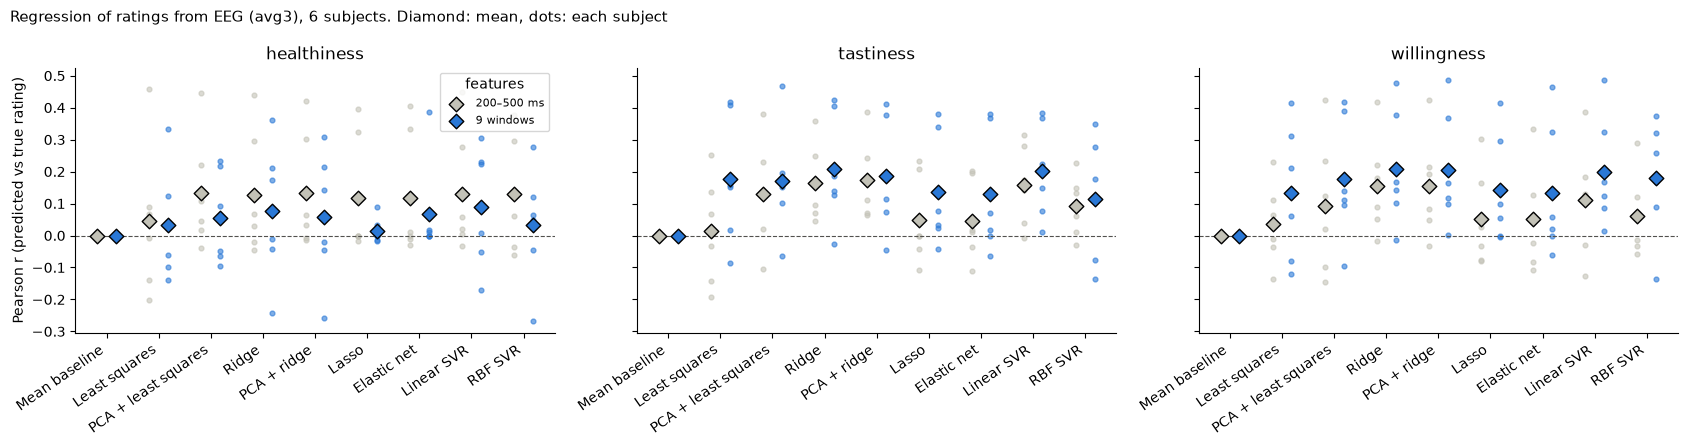

In [12]:
model_names = list(models)
colours = {"200–500 ms": "#c3c2b7", "9 windows": "#2a78d6"}
offsets = {"200–500 ms": -0.18, "9 windows": 0.18}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, target in zip(axes, TARGETS):
    for features in FEATURE_SETS:
        d = df[(df.target == target) & (df.features == features)]
        for i, name in enumerate(model_names):
            values = d[d.model == name].r.values
            x = i + offsets[features]
            ax.scatter(np.full(len(values), x), values, color=colours[features], s=12, alpha=0.6, zorder=2)
            ax.scatter(x, values.mean(), color=colours[features], edgecolor="black", marker="D", s=55, zorder=3,
                       label=features if i == 0 else None)
    ax.axhline(0, color="#52514e", linewidth=0.8, linestyle="--")
    ax.set_xticks(range(len(model_names)))
    ax.set_xticklabels(model_names, rotation=35, ha="right")
    ax.set_title(target)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Pearson r (predicted vs true rating)")
axes[0].legend(title="features", fontsize=8)
fig.suptitle(f"Regression of ratings from EEG ({VERSION}), 6 subjects. Diamond: mean, dots: each subject",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.savefig(f"regression_features_{VERSION}.png", dpi=200)
plt.show()

**Ridge, per subject:** r for each subject, target and feature set.

In [13]:
(df[df.model == "Ridge"].pivot(index="subject", columns=["target", "features"], values="r").round(3))

target,healthiness,tastiness,willingness,healthiness,tastiness,willingness
features,200–500 ms,200–500 ms,200–500 ms,9 windows,9 windows,9 windows
subject,,,,,,
sub-006,0.440,0.360,0.417,0.363,0.405,0.476
sub-008,-0.021,0.096,0.051,-0.242,-0.027,-0.013
sub-009,0.067,0.172,0.181,-0.041,0.140,0.143
sub-013,0.295,0.070,0.088,0.211,0.127,0.100
sub-014,-0.046,0.044,-0.018,-0.012,0.187,0.167
sub-015,0.031,0.250,0.219,0.173,0.423,0.377


Predicted vs true ratings for one subject (ridge, 9 windows). Each dot is one image if `AVERAGE_VIEWS`, otherwise one trial:

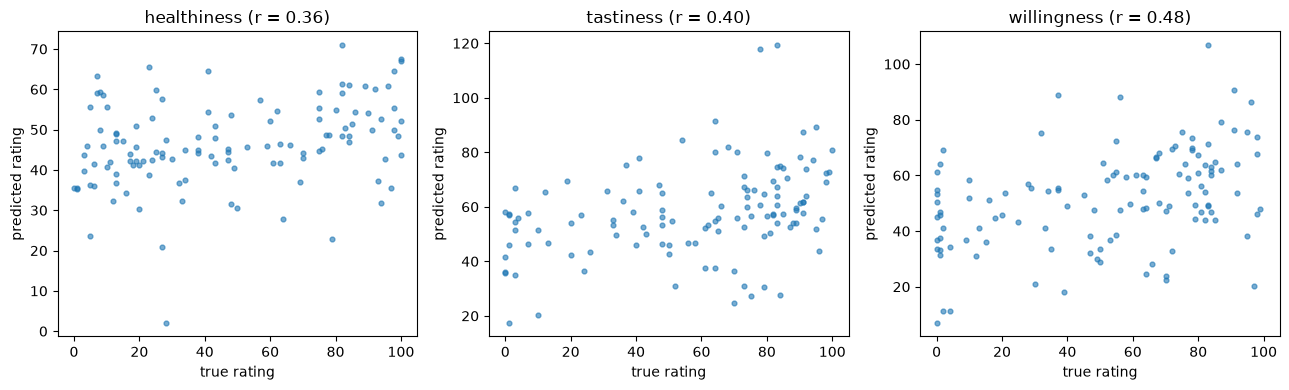

In [14]:
sub = "sub-006"
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, target in zip(axes, TARGETS):
    y_true, y_pred = predictions[sub, "9 windows", target, "Ridge"]
    r = df[(df.subject == sub) & (df.features == "9 windows") & (df.target == target)
           & (df.model == "Ridge")].r.item()
    ax.scatter(y_true, y_pred, s=12, alpha=0.6)
    ax.set(xlabel="true rating", ylabel="predicted rating", xlim=(-5, 105),
           title=f"{target} (r = {r:.2f})")
plt.tight_layout()
plt.show()

**Hyperparameters: are the chosen values still at the edge of the grid?** For each model, the share of folds where a chosen value is the smallest or largest of its list. A high share means the grid should be extended further in that direction.

In [15]:
def edge_report(name):
    """Most chosen values and share of folds at the edge of the grid, per feature set."""
    grid = models[name][1]
    rows = []
    for features in FEATURE_SETS:
        chosen = [p for plist in df[(df.model == name) & (df.features == features)].params for p in plist]
        for key, values in grid.items():
            param = key.split("__")[-1]
            numeric = [v for v in values if not isinstance(v, str)]
            picked = [p[param] for p in chosen]
            low = np.mean([v == min(numeric) for v in picked])
            high = np.mean([v == max(numeric) for v in picked])
            top = pd.Series([str(v) for v in picked]).value_counts().head(3)
            rows.append({"model": name, "features": features, "param": param,
                         "at lowest": f"{low:.0%}", "at highest": f"{high:.0%}",
                         "most chosen": ", ".join(f"{k} ({v})" for k, v in top.items())})
    return rows


pd.DataFrame([row for name, (_, grid) in models.items() if grid for row in edge_report(name)])

,model,features,param,at lowest,at highest,most chosen
0,PCA + least squares,200–500 ms,n_components,54%,0%,"1 (49), 2 (16), 10 (14)"
1,PCA + least squares,9 windows,n_components,48%,6%,"1 (43), 10 (21), 5 (8)"
2,Ridge,200–500 ms,alpha,0%,33%,"100000000.0 (30), 100.0 (20), 10000.0 (18)"
3,Ridge,9 windows,alpha,0%,22%,"1000.0 (26), 10000.0 (24), 100000000.0 (20)"
4,PCA + ridge,200–500 ms,n_components,37%,10%,"5 (33), 10 (19), 20 (17)"
5,PCA + ridge,200–500 ms,alpha,1%,31%,"1000000.0 (28), 10.0 (18), 1000.0 (17)"
6,PCA + ridge,9 windows,n_components,22%,34%,"60 (31), 10 (21), 5 (20)"
7,PCA + ridge,9 windows,alpha,0%,22%,"1000.0 (28), 10000.0 (20), 1000000.0 (20)"
8,Lasso,200–500 ms,alpha,0%,0%,"0.31622776601683794 (38), 0.1 (29), 1.0 (14)"
9,Lasso,9 windows,alpha,0%,0%,"1.0 (34), 0.31622776601683794 (33), 0.1 (21)"


## 7. Is r above chance?

### 7a. Per subject: shuffled ratings

With few examples, r fluctuates around 0 even with no signal. To know how large r gets **by chance**, we shuffle the ratings **between images** and rerun the exact same pipeline (ridge, both feature sets, 20 shuffles per subject and target). p = share of shuffled r ≥ real r; with 20 shuffles the smallest possible p is 1/21 ≈ 0.048. Use more shuffles (≥ 200) for the final report.

In [16]:
def shuffled_r(pipe, grid, X, y, groups, n_permutations=20, seed=0):
    """Pearson r obtained after shuffling the ratings between images."""
    rng = np.random.default_rng(seed)
    unique, first, inverse = np.unique(groups, return_index=True, return_inverse=True)
    rating_per_image = y[first]
    out = []
    for _ in range(n_permutations):
        y_perm = rng.permutation(rating_per_image)[inverse]
        y_pred, fold, _ = nested_cv(pipe, grid, X, y_perm, groups)
        out.append(scores(y_perm, y_pred, fold)["r"])
    return np.array(out)


pipe, grid = models["Ridge"]
chance = []
for sub in SUBJECTS:
    for features, windows in FEATURE_SETS.items():
        for target in TARGETS:
            X_feat, y, images = subject_data(sub, target, windows)
            null = shuffled_r(pipe, grid, X_feat, y, images)
            real = df[(df.subject == sub) & (df.features == features) & (df.target == target)
                      & (df.model == "Ridge")].r.item()
            chance.append({"subject": sub, "features": features, "target": target, "real_r": real,
                           "chance_mean": null.mean(), "chance_95%": np.percentile(null, 95),
                           "p_value": (np.sum(null >= real) + 1) / (len(null) + 1)})
    print(f"{sub} done")
chance = pd.DataFrame(chance)
chance.pivot(index="subject", columns=["target", "features"], values="p_value").round(3)

sub-006 done


sub-008 done


sub-009 done


sub-013 done


sub-014 done


sub-015 done


target,healthiness,tastiness,willingness,healthiness,tastiness,willingness
features,200–500 ms,200–500 ms,200–500 ms,9 windows,9 windows,9 windows
subject,,,,,,
sub-006,0.048,0.048,0.048,0.048,0.048,0.048
sub-008,0.667,0.143,0.286,0.952,0.333,0.429
sub-009,0.381,0.143,0.095,0.667,0.095,0.048
sub-013,0.048,0.286,0.286,0.095,0.095,0.238
sub-014,0.714,0.286,0.619,0.714,0.095,0.095
sub-015,0.476,0.095,0.048,0.143,0.048,0.048


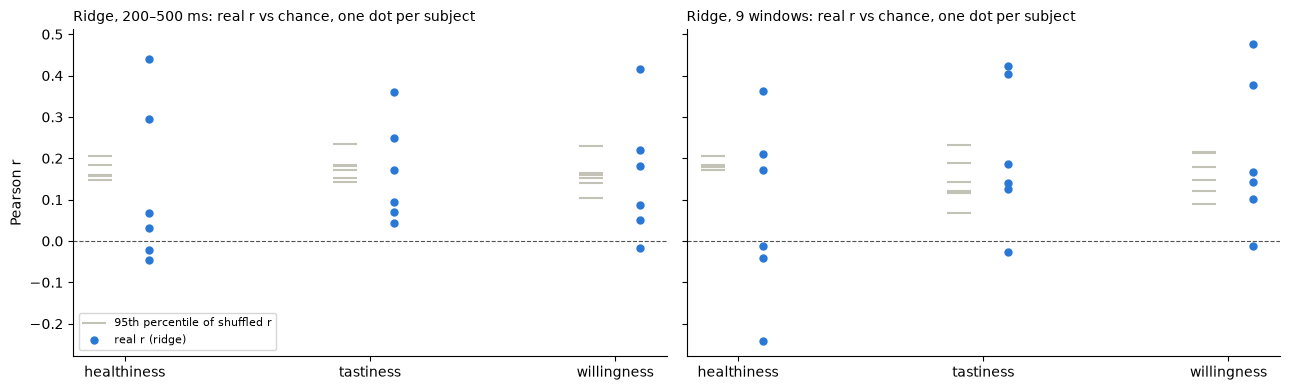

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, features in zip(axes, FEATURE_SETS):
    for i, target in enumerate(TARGETS):
        d = chance[(chance.target == target) & (chance.features == features)]
        ax.scatter(np.full(len(d), i) - 0.1, d["chance_95%"], color="#c3c2b7", marker="_", s=300,
                   label="95th percentile of shuffled r" if i == 0 else None)
        ax.scatter(np.full(len(d), i) + 0.1, d.real_r, color="#2a78d6", s=25,
                   label="real r (ridge)" if i == 0 else None)
    ax.axhline(0, color="#52514e", linewidth=0.8, linestyle="--")
    ax.set_xticks(range(3))
    ax.set_xticklabels(TARGETS)
    ax.set_title(f"Ridge, {features}: real r vs chance, one dot per subject", loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Pearson r")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 7b. Across subjects: is r > 0 on average?

The question that matters for a general conclusion: over the 6 subjects, is r above 0? One-sided t-test on the Fisher-z values, and the Wilcoxon signed-rank test (no normality assumption). With only 6 subjects these tests have little power. Tastiness and willingness are strongly correlated targets, so they are not two independent findings.

In [18]:
group = []
for (features, target, name), d in df[df.model.isin(["Ridge", "PCA + ridge", "PCA + least squares", "Linear SVR"])].groupby(
        ["features", "target", "model"], sort=False):
    r = d.r.values
    group.append({"model": name, "features": features, "target": target, "mean_r": r.mean(),
                  "subjects r > 0": f"{int((r > 0).sum())}/{len(r)}",
                  "p (t-test)": stats.ttest_1samp(np.arctanh(r), 0, alternative="greater").pvalue,
                  "p (Wilcoxon)": stats.wilcoxon(r, alternative="greater").pvalue})
pd.DataFrame(group).round(3)

,model,features,target,mean_r,subjects r > 0,p (t-test),p (Wilcoxon)
0,PCA + least squares,200–500 ms,healthiness,0.134,5/6,0.065,0.047
1,Ridge,200–500 ms,healthiness,0.127,4/6,0.087,0.109
2,PCA + ridge,200–500 ms,healthiness,0.132,4/6,0.070,0.078
3,Linear SVR,200–500 ms,healthiness,0.129,5/6,0.081,0.078
4,PCA + least squares,200–500 ms,tastiness,0.130,5/6,0.058,0.047
5,Ridge,200–500 ms,tastiness,0.165,6/6,0.011,0.016
6,PCA + ridge,200–500 ms,tastiness,0.173,6/6,0.010,0.016
7,Linear SVR,200–500 ms,tastiness,0.156,5/6,0.016,0.031
8,PCA + least squares,200–500 ms,willingness,0.093,4/6,0.167,0.219
9,Ridge,200–500 ms,willingness,0.156,5/6,0.030,0.031


## 8. Time-resolved regression: *when* is the rating information present?

Instead of fixed windows, we slide a **50 ms window every 20 ms** from −100 to 1000 ms and fit one ridge per position (with the 3 views averaged). This gives an **r(t) curve**, like Fig. 2E–F of the article. The period before the image (−100 → 0 ms) cannot contain information about the image, so it shows what chance looks like.

To keep it fast, ridge chooses α with `RidgeCV` (efficient leave-one-out on the training images) instead of a nested grid search. This is valid because with averaged views there is one row per image, so leave-one-out never splits an image.

In [19]:
CENTRES = np.arange(-75, 976, 20)              # window centres (ms): windows [c - 25, c + 25]
ridge_cv = model(RidgeCV(alphas=np.logspace(-1, 8, 10)))


def time_resolved_r(subject, target):
    """r(t) for one subject and target, using the same outer folds at every time point."""
    windows = [(c - 25, c + 25) for c in CENTRES]
    folds = None
    curve = []
    for window in windows:
        X_t, y, images = subject_data(subject, target, [window], average=True)
        if folds is None:
            folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=0).split(X_t, y, images))
        z = []
        for train, test in folds:
            y_pred = ridge_cv.fit(X_t[train], y[train]).predict(X_t[test])
            z.append(np.arctanh(np.clip(pearson(y[test], y_pred), -0.999, 0.999)))
        curve.append(np.tanh(np.mean(z)))
    return np.array(curve)


curves = {target: np.array([time_resolved_r(sub, target) for sub in SUBJECTS]) for target in TARGETS}
print("done")

done


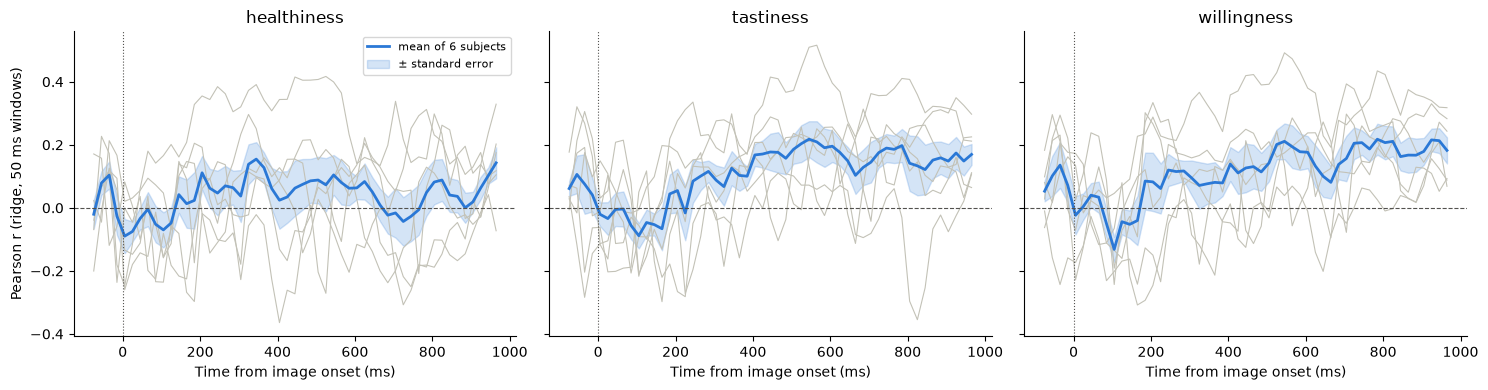

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, target in zip(axes, TARGETS):
    c = curves[target]                                # (subjects, time)
    for curve in c:
        ax.plot(CENTRES, curve, color="#c3c2b7", linewidth=0.8)
    mean, sem = c.mean(axis=0), c.std(axis=0) / np.sqrt(len(c))
    ax.plot(CENTRES, mean, color="#2a78d6", linewidth=2, label="mean of 6 subjects")
    ax.fill_between(CENTRES, mean - sem, mean + sem, color="#2a78d6", alpha=0.2, label="± standard error")
    ax.axhline(0, color="#52514e", linewidth=0.8, linestyle="--")
    ax.axvline(0, color="#52514e", linewidth=0.8, linestyle=":")
    ax.set(title=target, xlabel="Time from image onset (ms)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Pearson r (ridge, 50 ms windows)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("regression_time_resolved.png", dpi=200)
plt.show()

In [21]:
# Mean r per period: before the image (chance reference) and after
periods = {"−100–0 ms (before image)": (-100, 0), "100–300 ms": (100, 300),
           "300–600 ms": (300, 600), "600–1000 ms": (600, 1000)}
pd.DataFrame({target: {name: curves[target][:, (CENTRES >= a) & (CENTRES < b)].mean()
                       for name, (a, b) in periods.items()} for target in TARGETS}).round(3)

,healthiness,tastiness,willingness
−100–0 ms (before image),0.034,0.071,0.090
100–300 ms,0.032,0.013,0.031
300–600 ms,0.081,0.156,0.130
600–1000 ms,0.038,0.157,0.174


In [22]:
df_save = df.drop(columns="params").copy()
df_save.to_csv(f"regression_features_{VERSION}_detail.csv", index=False)
summary.to_csv(f"regression_features_{VERSION}_summary.csv")
chance.to_csv(f"regression_features_{VERSION}_chance.csv", index=False)
print("Saved as version", VERSION)

Saved as version avg3


### Comparison with the previous runs

Mean r over the 6 subjects. The two first columns come from the earlier runs (200–500 ms, old grids), saved in `regression_benchmark_6subjects_360_detail.csv` and `..._avg3_detail.csv`.

In [23]:
runs = {}
for label, path in [("360 trials, 200–500, old grids", "regression_benchmark_6subjects_360_detail.csv"),
                    ("avg3, 200–500, old grids", "regression_benchmark_6subjects_avg3_detail.csv")]:
    if Path(path).is_file():
        runs[label] = pd.read_csv(path).groupby(["target", "model"], sort=False).r.mean()
for features in FEATURE_SETS:
    runs[f"{VERSION}, {features}, new grids"] = (df[df.features == features]
                                                 .groupby(["target", "model"], sort=False).r.mean())
pd.DataFrame(runs).round(3)

360 trials, 200–500, old grids  \
target      model                                                 
healthiness Elastic net                                   0.070   
            Lasso                                         0.067   
            Least squares                                 0.025   
            Linear SVR                                    0.068   
            Mean baseline                                 0.000   
            PCA + least squares                             NaN   
            PCA + ridge                                     NaN   
            RBF SVR                                       0.055   
            Ridge                                         0.077   
tastiness   Elastic net                                   0.040   
            Lasso                                         0.042   
            Least squares                                 0.042   
            Linear SVR                                    0.098   
            Mean baseline                                 0.000   
            PCA + least squares                             NaN   
            PCA + ridge                                     NaN   
            RBF SVR                                       0.106   
            Ridge                                         0.098   
willingness Elastic net                                   0.035   
            Lasso                                         0.034   
            Least squares                                 0.035   
            Linear SVR                                    0.078   
            Mean baseline                                 0.000   
            PCA + least squares                             NaN   
            PCA + ridge                                     NaN   
            RBF SVR                                       0.098   
            Ridge                                         0.091   

                                 avg3, 200–500, old grids  \
target      model                                           
healthiness Elastic net                             0.127   
            Lasso                                   0.117   
            Least squares                           0.044   
            Linear SVR                              0.125   
            Mean baseline                           0.000   
            PCA + least squares                       NaN   
            PCA + ridge                               NaN   
            RBF SVR                                 0.119   
            Ridge                                   0.126   
tastiness   Elastic net                             0.045   
            Lasso                                   0.048   
            Least squares                           0.015   
            Linear SVR                              0.158   
            Mean baseline                           0.000   
            PCA + least squares                       NaN   
            PCA + ridge                               NaN   
            RBF SVR                                 0.112   
            Ridge                                   0.166   
willingness Elastic net                             0.060   
            Lasso                                   0.050   
            Least squares                           0.037   
            Linear SVR                              0.113   
            Mean baseline                           0.000   
            PCA + least squares                       NaN   
            PCA + ridge                               NaN   
            RBF SVR                                 0.071   
            Ridge                                   0.156   

                                 avg3, 200–500 ms, new grids  \
target      model                                              
healthiness Elastic net                                0.118   
            Lasso                                      0.117   
            Least squares                              0.044   

## 9. Choosing the windows inside the cross-validation

Sections 6–7 suggest that healthiness works better with the single 200–500 ms window, and tastiness / willingness with the 9 windows. But picking, for each rating, the feature set that scored best on these 6 subjects would make the reported r **optimistic** (part of the difference may be luck).

The clean way: treat **"which feature set"** as one more hyperparameter. In each outer fold, the inner cross-validation tries both feature sets (together with α or C) on the training images only, keeps the best combination, and the held-out images measure the result. The score then includes the cost of making the choice.

How it works in code: X contains both feature sets side by side (64 + 576 = 640 columns), and a small `SelectFeatures` step keeps only the columns of the feature set being tried. `GridSearchCV` treats its `features` setting like any other hyperparameter.

In [24]:
from sklearn.base import BaseEstimator, TransformerMixin

COLUMNS = {"200–500 ms": slice(0, 64), "9 windows": slice(64, 64 + 576)}


class SelectFeatures(BaseEstimator, TransformerMixin):
    """Keep only the columns of one feature set (a hyperparameter tuned by GridSearchCV)."""

    def __init__(self, features="9 windows"):
        self.features = features

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X[:, COLUMNS[self.features]]


def both_feature_sets(subject, target):
    """X with the 200-500 ms features (64 columns) followed by the 9-window features (576 columns)."""
    X_one, y, images = subject_data(subject, target, FEATURE_SETS["200–500 ms"])
    X_nine, _, _ = subject_data(subject, target, FEATURE_SETS["9 windows"])
    return np.hstack([X_one, X_nine]), y, images


choice = [P + "selectfeatures__features"]
selection_models = {
    "Ridge": (model(SelectFeatures(), Ridge()),
              {choice[0]: list(COLUMNS), P + "ridge__alpha": np.logspace(-1, 8, 10)}),
    "Linear SVR": (model(SelectFeatures(), SVR(kernel="linear")),
                   {choice[0]: list(COLUMNS), P + "svr__C": np.logspace(-7, -1, 7)}),
}

selection = []
for sub in SUBJECTS:
    for target in TARGETS:
        X_both, y, images = both_feature_sets(sub, target)
        for name, (pipe, grid) in selection_models.items():
            y_pred, fold, chosen = nested_cv(pipe, grid, X_both, y, images)
            selection.append({"subject": sub, "target": target, "model": name, **scores(y, y_pred, fold),
                              "chosen features": [p["features"] for p in chosen]})
selection = pd.DataFrame(selection)
print("done")

done


**Which feature set did the inner cross-validation choose?** Share of the 30 folds (6 subjects × 5 folds) where each feature set was picked:

In [25]:
picked = (selection.explode("chosen features")
                 .groupby(["model", "target"], sort=False)["chosen features"]
                 .value_counts(normalize=True).unstack(fill_value=0))
(picked * 100).round(0).astype(int).astype(str) + "%" 

chosen features        200–500 ms 9 windows
model      target                          
Ridge      healthiness        70%       30%
           tastiness          23%       77%
           willingness        33%       67%
Linear SVR healthiness        73%       27%
           tastiness          30%       70%
           willingness        40%       60%

**Mean r: fixed feature sets vs chosen inside the cross-validation.** The "chosen in CV" column is the honest estimate of what "pick the best windows for each rating" gives.

In [26]:
fixed = df[df.model.isin(selection_models)].pivot_table(index=["model", "target"], columns="features",
                                                         values="r", aggfunc="mean", sort=False)
fixed["chosen in CV"] = selection.groupby(["model", "target"], sort=False).r.mean()
fixed.round(3)

features                200–500 ms  9 windows  chosen in CV
model      target                                          
Ridge      healthiness       0.127      0.075         0.137
           tastiness         0.165      0.209         0.197
           willingness       0.156      0.209         0.187
Linear SVR healthiness       0.129      0.090         0.149
           tastiness         0.156      0.201         0.157
           willingness       0.111      0.200         0.166

In [27]:
group = []
for (name, target), d in selection.groupby(["model", "target"], sort=False):
    r = d.r.values
    group.append({"model": name, "target": target, "mean_r": r.mean(),
                  "subjects r > 0": f"{int((r > 0).sum())}/{len(r)}",
                  "p (t-test)": stats.ttest_1samp(np.arctanh(r), 0, alternative="greater").pvalue,
                  "p (Wilcoxon)": stats.wilcoxon(r, alternative="greater").pvalue})
print("Across subjects, feature set chosen inside the CV:")
pd.DataFrame(group).round(3)

Across subjects, feature set chosen inside the CV:


,model,target,mean_r,subjects r > 0,p (t-test),p (Wilcoxon)
0,Ridge,healthiness,0.137,4/6,0.071,0.109
1,Linear SVR,healthiness,0.149,4/6,0.057,0.156
2,Ridge,tastiness,0.197,6/6,0.017,0.016
3,Linear SVR,tastiness,0.157,5/6,0.022,0.031
4,Ridge,willingness,0.187,6/6,0.034,0.016
5,Linear SVR,willingness,0.166,5/6,0.055,0.047


In [28]:
selection.drop(columns="chosen features").to_csv(f"regression_window_choice_{VERSION}_detail.csv", index=False)
print("Saved.")

Saved.


## 10. Interpretation and next steps

*To be completed after looking at the results above.*

**Next methods to add, following the course:**
1. ✅ **Dimensionality reduction**: PCA before least squares / ridge.
2. **Kernel ridge regression** and **polynomial features** (non-linear models from the course).
3. **k-nearest neighbours regression**, **trees / random forests**, small **neural network** (MLPRegressor).
4. **Across-subject model**: train on 5 subjects, test on the 6th (needs per-subject standardisation).
5. **More participants** as an independent test set: fix the final pipeline on these 6, then run it once on new participants.